In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

In [2]:
# Load all datasets from the results directory
# Pattern: "scoring/{anonymization_method}/{embedding_method}/{aggregation_method}/scores.parquet"
SCORES_PATH = Path("../../results/scoring")

_scores = []
for anonymization_method in SCORES_PATH.iterdir():
    if not anonymization_method.is_dir():
        continue
    for embedding_method in anonymization_method.iterdir():
        if not embedding_method.is_dir():
            continue
        for aggregation_method in embedding_method.iterdir():
            if not aggregation_method.is_dir():
                continue
            _score = pd.read_parquet(str(aggregation_method / "scores.parquet"))
            for _, _s in _score.iterrows():
                _scores.append(
                    {
                        "key": f"{anonymization_method.name}/{embedding_method.name}/{aggregation_method.name}",
                        "anonymization_method": anonymization_method.name,
                        "embedding_method": embedding_method.name,
                        "aggregation_method": aggregation_method.name,
                        "accuracy": _s["top-1"],
                        "frame_accuracy": _s["frame-top-1"],
                    }
                )
scores = pd.DataFrame(_scores)
scores.to_parquet(Path("../../results/all.parquet"))
scores.to_csv(Path("../../results/all.csv"))
scores

,key,anonymization_method,embedding_method,aggregation_method,accuracy,frame_accuracy
0,gaussianblur/ghostfacenet/consensus_beta5,gaussianblur,ghostfacenet,consensus_beta5,0.158103,0.158103
1,gaussianblur/ghostfacenet/consensus_beta5,gaussianblur,ghostfacenet,consensus_beta5,0.182432,0.182432
2,gaussianblur/ghostfacenet/consensus_beta5,gaussianblur,ghostfacenet,consensus_beta5,0.181146,0.181146
3,gaussianblur/ghostfacenet/consensus_beta20,gaussianblur,ghostfacenet,consensus_beta20,0.146245,0.146245
4,gaussianblur/ghostfacenet/consensus_beta20,gaussianblur,ghostfacenet,consensus_beta20,0.155405,0.155405
...,...,...,...,...,...,...
715,none/facenet512/none,none,facenet512,none,0.736486,0.597732
716,none/facenet512/none,none,facenet512,none,0.713494,0.588309
717,none/facenet512/pooling_median,none,facenet512,pooling_median,0.662714,0.662714
718,none/facenet512/pooling_median,none,facenet512,pooling_median,0.684122,0.684122


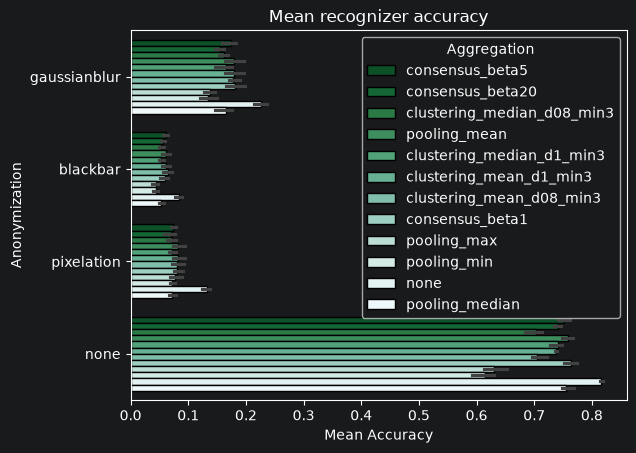

In [3]:
# Visualize the mean accuracy (with error bars) for each combination of aggregation and anonymization method.

filtered_scores = scores[(scores["embedding_method"] == "ghostfacenet")]
sns.barplot(
    data=filtered_scores,
    y="anonymization_method",
    x="accuracy",
    orient="h",
    hue="aggregation_method",
    palette=sns.color_palette("BuGn_r", n_colors=len(filtered_scores["aggregation_method"].unique())),
    ec="k",
)

plt.title("Mean recognizer accuracy")
plt.xlabel("Mean Accuracy")
plt.ylabel("Anonymization")
legend = plt.legend(title='Aggregation', loc='upper right')
plt.show()

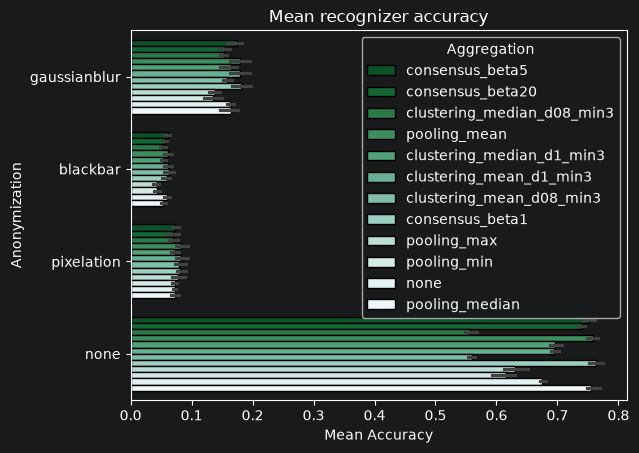

In [4]:
filtered_scores = scores[(scores["embedding_method"] == "ghostfacenet")]
sns.barplot(
    data=filtered_scores,
    y="anonymization_method",
    x="frame_accuracy",
    orient="h",
    hue="aggregation_method",
    palette=sns.color_palette("BuGn_r", n_colors=len(filtered_scores["aggregation_method"].unique())),
    ec="k",
)

plt.title("Mean recognizer accuracy")
plt.xlabel("Mean Accuracy")
plt.ylabel("Anonymization")
legend = plt.legend(title='Aggregation', loc='upper right')
plt.show()

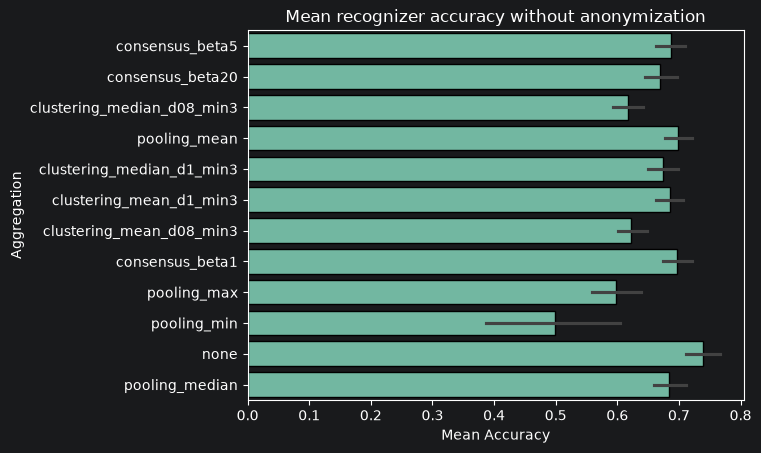

In [5]:
# Visualize the mean accuracy (with error bars) for each aggregation method without anonymization.

filtered_scores = scores[(scores["anonymization_method"] == "none")]
sns.barplot(
    data=filtered_scores,
    y="aggregation_method",
    x="accuracy",
    orient="h",
    hue="anonymization_method",
    palette=sns.color_palette("BuGn_r", n_colors=len(filtered_scores["anonymization_method"].unique())),
    ec="k",
    legend=False,
)

plt.title("Mean recognizer accuracy without anonymization")
plt.xlabel("Mean Accuracy")
plt.ylabel("Aggregation")
plt.show()

## Recognizer performance without aggregation

Frame-level baseline (`aggregation_method == "none"`) for each embedding model, across anonymization methods.

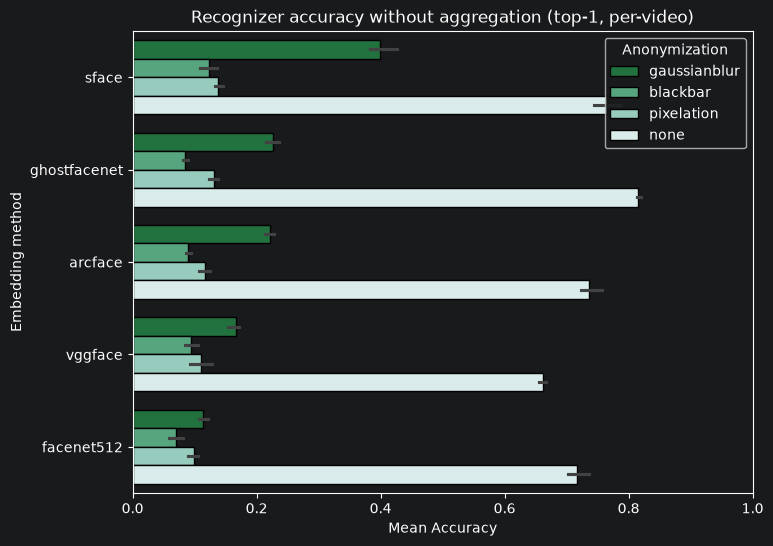

In [6]:
# Recognizer accuracy without aggregation (frame-level baseline), by embedding method and anonymization.

no_agg = scores[scores["aggregation_method"] == "none"]
embedding_order = (
    no_agg.groupby("embedding_method")["accuracy"].mean().sort_values(ascending=False).index
)

plt.figure(figsize=(8, 6))
sns.barplot(
    data=no_agg,
    y="embedding_method",
    x="accuracy",
    order=embedding_order,
    orient="h",
    hue="anonymization_method",
    palette=sns.color_palette("BuGn_r", n_colors=no_agg["anonymization_method"].nunique()),
    ec="k",
)

plt.title("Recognizer accuracy without aggregation (top-1, per-video)")
plt.xlabel("Mean Accuracy")
plt.ylabel("Embedding method")
plt.legend(title="Anonymization", loc="upper right")
plt.xlim(right=1.0)
plt.show()

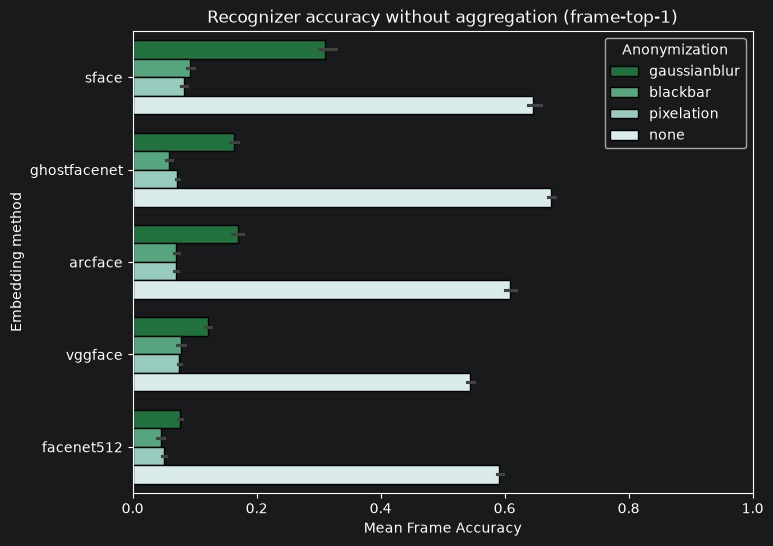

In [7]:
# Same comparison at frame level (frame-top-1) rather than pooled per-video.

plt.figure(figsize=(8, 6))
sns.barplot(
    data=no_agg,
    y="embedding_method",
    x="frame_accuracy",
    order=embedding_order,
    orient="h",
    hue="anonymization_method",
    palette=sns.color_palette("BuGn_r", n_colors=no_agg["anonymization_method"].nunique()),
    ec="k",
)

plt.title("Recognizer accuracy without aggregation (frame-top-1)")
plt.xlabel("Mean Frame Accuracy")
plt.ylabel("Embedding method")
plt.legend(title="Anonymization", loc="upper right")
plt.xlim(right=1.0)
plt.show()

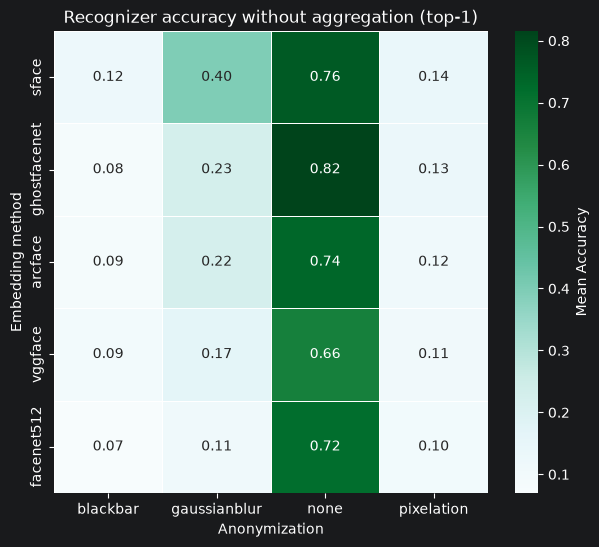

In [8]:
# Same data as a heatmap: which embedding model holds up best under which anonymization?

pivot_no_agg = no_agg.pivot_table(
    index="embedding_method", columns="anonymization_method", values="accuracy", aggfunc="mean"
).loc[embedding_order]

plt.figure(figsize=(7, 6))
sns.heatmap(pivot_no_agg, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Recognizer accuracy without aggregation (top-1)")
plt.xlabel("Anonymization")
plt.ylabel("Embedding method")
plt.show()

## Aggregation method performance across anonymizations and recognizers

How much does feature-level aggregation (pooling / clustering) help over the frame-level (`none`) baseline,
and does that depend on the anonymization method or the embedding model?

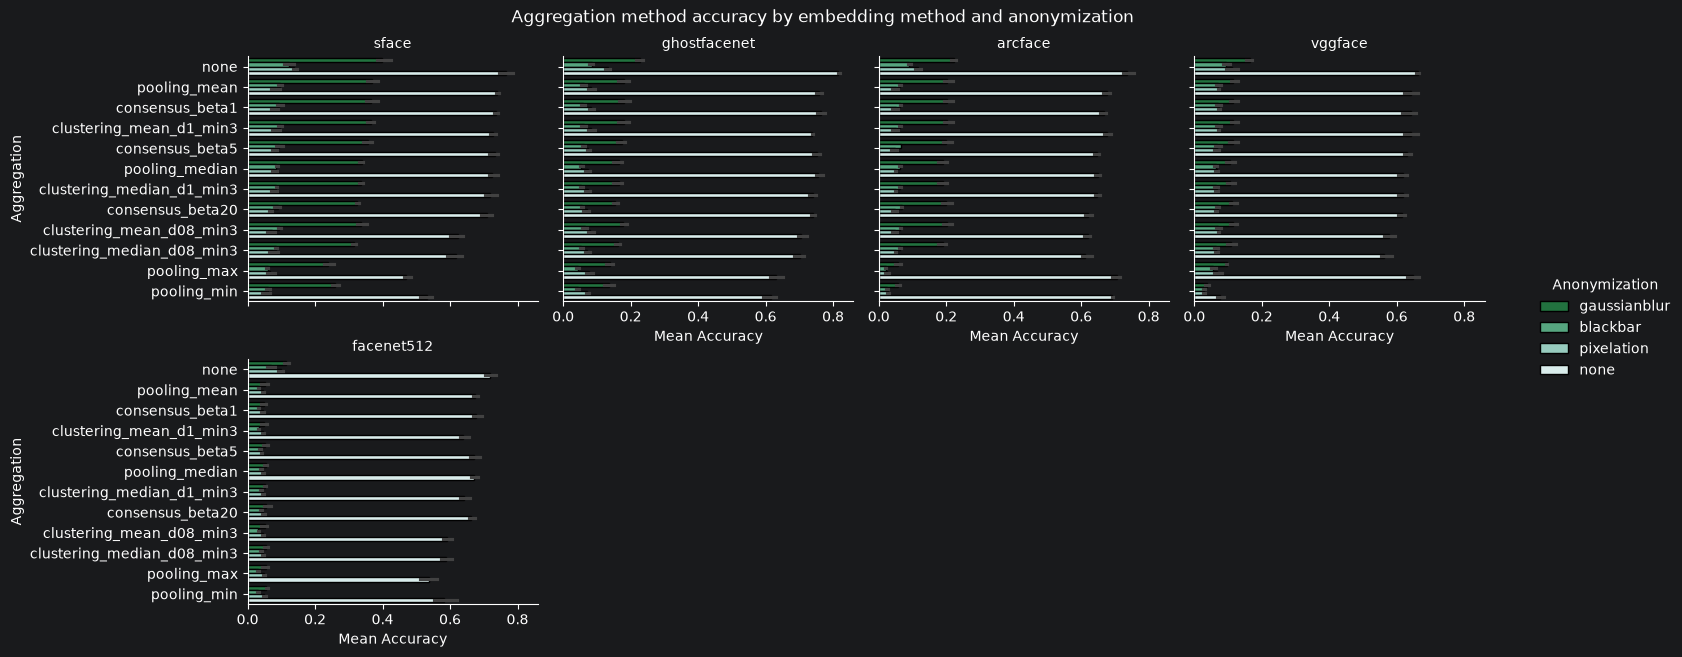

In [9]:
# One panel per embedding method: aggregation method (y) vs. accuracy (x), colored by anonymization.

agg_order = (
    scores.groupby("aggregation_method")["accuracy"].mean().sort_values(ascending=False).index
)

grid = sns.catplot(
    data=scores,
    kind="bar",
    y="aggregation_method",
    x="accuracy",
    order=agg_order,
    orient="h",
    hue="anonymization_method",
    col="embedding_method",
    col_wrap=4,
    col_order=embedding_order,
    palette=sns.color_palette("BuGn_r", n_colors=scores["anonymization_method"].nunique()),
    ec="k",
    height=3.2,
    aspect=1.2,
    legend_out=True,
)

grid.set_titles("{col_name}")
grid.set_axis_labels("Mean Accuracy", "Aggregation")
grid.legend.set_title("Anonymization")
grid.fig.suptitle("Aggregation method accuracy by embedding method and anonymization", y=1.02)
plt.show()

### Summary heatmaps

The facet grid above is exhaustive; these two heatmaps collapse it along one dimension at a time to make the
overall trends easier to read.

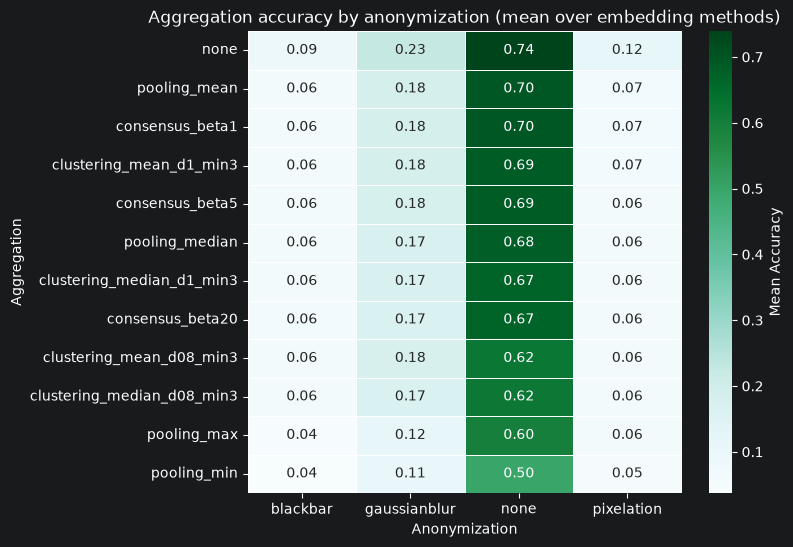

In [10]:
# Aggregation method vs. anonymization, averaged over all embedding models.
biased_embeddings = ["deepid", "openface"]
unbiased_scores = scores[~scores["embedding_method"].isin(biased_embeddings)]

pivot_agg_anon = unbiased_scores.pivot_table(
    index="aggregation_method", columns="anonymization_method", values="accuracy", aggfunc="mean"
).loc[agg_order]

plt.figure(figsize=(7, 6))
sns.heatmap(pivot_agg_anon, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy by anonymization (mean over embedding methods)")
plt.xlabel("Anonymization")
plt.ylabel("Aggregation")
plt.show()

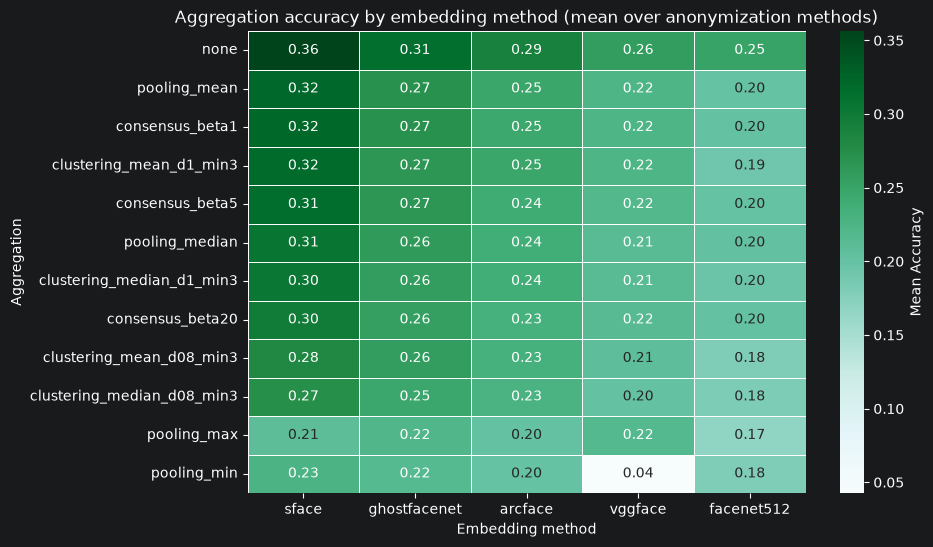

In [11]:
# Aggregation method vs. embedding model, averaged over all anonymization methods.

pivot_agg_embed = scores.pivot_table(
    index="aggregation_method", columns="embedding_method", values="accuracy", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_agg_embed, annot=True, fmt=".2f", cmap="BuGn", cbar_kws={"label": "Mean Accuracy"}, linewidths=0.5, linecolor="w")

plt.title("Aggregation accuracy by embedding method (mean over anonymization methods)")
plt.xlabel("Embedding method")
plt.ylabel("Aggregation")
plt.show()

### Aggregation gain, isolated from embedding/anonymization bias

The heatmaps above average raw accuracy across embedding methods and anonymization methods, but those two
factors dominate the accuracy *scale* (e.g. arcface vs. deepid, or `none` vs. `pixelation`) and can swamp the
comparison between aggregation methods themselves. To isolate the aggregation effect, normalize each
aggregation method's accuracy against the frame-level (`aggregation_method == "none"`) baseline *within* its
own (anonymization, embedding) pair before averaging across pairs, and drop `deepid`/`openface`, which
underperform every other embedding method badly enough to add noise rather than signal to the pooled result.

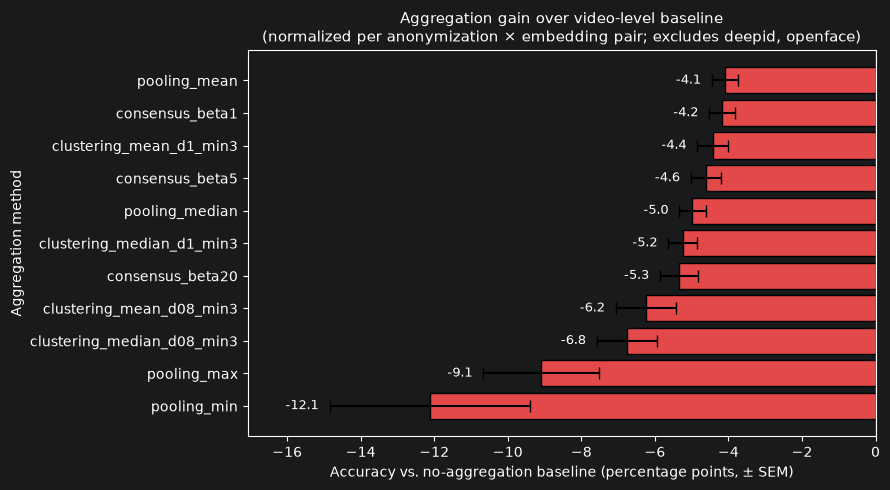

In [12]:
biased_embeddings = ["deepid", "openface"]
unbiased_scores = scores[~scores["embedding_method"].isin(biased_embeddings)]

pair_means = (
    unbiased_scores.groupby(["anonymization_method", "embedding_method", "aggregation_method"])["accuracy"]
    .mean()
    .reset_index()
)
baseline = pair_means[pair_means["aggregation_method"] == "none"][
    ["anonymization_method", "embedding_method", "accuracy"]
].rename(columns={"accuracy": "baseline_accuracy"})

# Gain of each aggregation method over the frame-level baseline, computed per (anonymization, embedding) pair
# so the comparison is unaffected by how strong that particular pair's baseline accuracy happens to be.
relative = pair_means.merge(baseline, on=["anonymization_method", "embedding_method"])
relative["gain_pp"] = (relative["accuracy"] - relative["baseline_accuracy"]) * 100
relative = relative[relative["aggregation_method"] != "none"]

summary = (
    relative.groupby("aggregation_method")["gain_pp"]
    .agg(mean="mean", sem="sem", n="count")
    .sort_values("mean")
)

colors = ["#2a78d6" if v >= 0 else "#e34948" for v in summary["mean"]]
fig, ax = plt.subplots(figsize=(9, 5))
y_pos = range(len(summary))
ax.barh(y_pos, summary["mean"], xerr=summary["sem"], color=colors, ec="k", capsize=4)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(summary.index)
ax.axvline(0, color="#898781", linewidth=1)

for y, mean, sem in zip(y_pos, summary["mean"], summary["sem"]):
    label_x = mean + sem + 0.3 if mean >= 0 else mean - sem - 0.3
    ax.text(label_x, y, f"{mean:+.1f}", va="center", ha="left" if mean >= 0 else "right", fontsize=9)
ax.margins(x=0.15)

ax.set_title(
    "Aggregation gain over video-level baseline\n"
    f"(normalized per anonymization × embedding pair; excludes {', '.join(biased_embeddings)})",
    fontsize=11,
)
ax.set_xlabel("Accuracy vs. no-aggregation baseline (percentage points, ± SEM)")
ax.set_ylabel("Aggregation method")
fig.tight_layout()
plt.show()

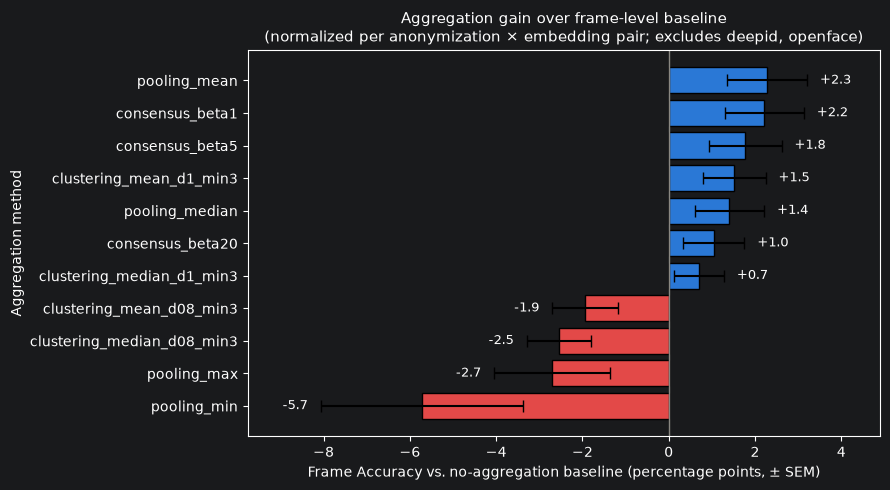

In [13]:
biased_embeddings = ["deepid", "openface"]
unbiased_scores = scores[~scores["embedding_method"].isin(biased_embeddings)]

pair_means = (
    unbiased_scores.groupby(["anonymization_method", "embedding_method", "aggregation_method"])["frame_accuracy"]
    .mean()
    .reset_index()
)
baseline = pair_means[pair_means["aggregation_method"] == "none"][
    ["anonymization_method", "embedding_method", "frame_accuracy"]
].rename(columns={"frame_accuracy": "baseline_frame_accuracy"})

# Gain of each aggregation method over the frame-level baseline, computed per (anonymization, embedding) pair
# so the comparison is unaffected by how strong that particular pair's baseline frame_accuracy happens to be.
relative = pair_means.merge(baseline, on=["anonymization_method", "embedding_method"])
relative["gain_pp"] = (relative["frame_accuracy"] - relative["baseline_frame_accuracy"]) * 100
relative = relative[relative["aggregation_method"] != "none"]

summary = (
    relative.groupby("aggregation_method")["gain_pp"]
    .agg(mean="mean", sem="sem", n="count")
    .sort_values("mean")
)

colors = ["#2a78d6" if v >= 0 else "#e34948" for v in summary["mean"]]
fig, ax = plt.subplots(figsize=(9, 5))
y_pos = range(len(summary))
ax.barh(y_pos, summary["mean"], xerr=summary["sem"], color=colors, ec="k", capsize=4)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(summary.index)
ax.axvline(0, color="#898781", linewidth=1)

for y, mean, sem in zip(y_pos, summary["mean"], summary["sem"]):
    label_x = mean + sem + 0.3 if mean >= 0 else mean - sem - 0.3
    ax.text(label_x, y, f"{mean:+.1f}", va="center", ha="left" if mean >= 0 else "right", fontsize=9)
ax.margins(x=0.15)

ax.set_title(
    "Aggregation gain over frame-level baseline\n"
    f"(normalized per anonymization × embedding pair; excludes {', '.join(biased_embeddings)})",
    fontsize=11,
)
ax.set_xlabel("Frame Accuracy vs. no-aggregation baseline (percentage points, ± SEM)")
ax.set_ylabel("Aggregation method")
fig.tight_layout()
plt.show()